In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
plt.rcParams['axes.grid'] = False

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.metrics import roc_curve, auc, precision_recall_curve
import time

from RADON_AE_SAD import RADON, fit
from Preprocessing import get_data, plot_distribution, preprocess_dataset, create_dataloaders
from Training import train_radon_debug, train_radon_simple, plot_training_losses
from Testing import evaluate_and_plot, plot_aucroc, plot_auprc, visualize_mnist_reconstruction, explain_nslkdd

In [2]:
torch.__version__

'2.9.1+cpu'

## Selecting the GPU

In [3]:
#Check if GPU is available and select the available device
print(torch.cuda.is_available())
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

False


# Import the dataset

In [5]:
DATA_DIR = r"c:\Users\giuse\Desktop\giuseppe\Machine e deep learning\RADON\data"

dataset="NSL_KDD"  # "MNIST" o "NSL_KDD"

if dataset.upper() == "MNIST":
    # 1. Carica MNIST
    X_train_all, Y_train_all, X_test_all, Y_test_all, _ = get_data("MNIST", DATA_DIR, flatten=True)
    print("\n--- Verifica Dimensioni ---")
    print(f"MNIST Train: {X_train_all.shape}")
else:
    # 2. Carica NSL-KDD
    X_train_all, Y_train_all, X_test_all, Y_test_all, feature_names= get_data("NSL_KDD", DATA_DIR)
    X_test_all = torch.clamp(X_test_all, 0.0, 1.0)
    print("\n--- Verifica Dimensioni ---")
    print(f"KDD Train:   {X_train_all.shape}")

[Loader] Richiesto: NSL_KDD | Root: c:\Users\giuse\Desktop\giuseppe\Machine e deep learning\RADON\data
Caricamento tensori NSL-KDD...
NSL-KDD caricato. X_train: torch.Size([125973, 122]), Y_train: torch.Size([125973])

--- Verifica Dimensioni ---
KDD Train:   torch.Size([125973, 122])


In [6]:
print("X_train:", X_train_all.shape, "Y_train:", Y_train_all.shape, "labels:", torch.unique(Y_train_all).tolist()[:10])
print("X_test :", X_test_all.shape,  "Y_test :", Y_test_all.shape,  "labels:", torch.unique(Y_test_all).tolist()[:10])
print("Range X_train:", (float(X_train_all.min()), float(X_train_all.max())))
print("Range X_test :", (float(X_test_all.min()), float(X_test_all.max())))

X_train: torch.Size([125973, 122]) Y_train: torch.Size([125973]) labels: [0, 1]
X_test : torch.Size([22544, 122]) Y_test : torch.Size([22544]) labels: [0, 1]
Range X_train: (0.0, 1.0)
Range X_test : (0.0, 1.0)


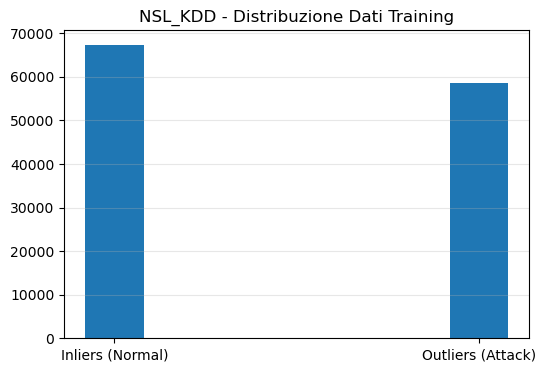

------------------------------
Statistiche NSL_KDD
------------------------------
Inliers      : 67343
Outliers     : 58630
Totale       : 125973
Contaminazione: 0.4654 (46.54%)
------------------------------


In [7]:
if dataset.upper() == "MNIST":
    Y_train_binary_m = plot_distribution(Y_train_all, "MNIST", normal_class=4)
else:
    plot_distribution(Y_train_all, "NSL_KDD")

# Data preprocessing


Preprocessing specifico per: NSL_KDD
   Statistiche originali -> Inliers: 67343, Outliers disponibili: 58630
   Target contaminazione: 5.0% -> Outliers richiesti: 3544
   TRAIN completato: torch.Size([70887, 122]) | Contaminazione effettiva: 0.0500


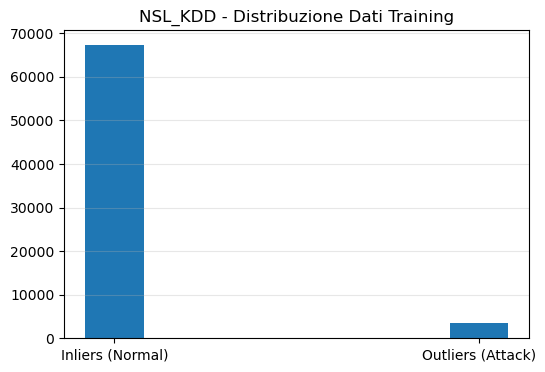

------------------------------
Statistiche NSL_KDD
------------------------------
Inliers      : 67343
Outliers     : 3544
Totale       : 70887
Contaminazione: 0.0500 (5.00%)
------------------------------


In [8]:
target_contamination = 0.05
if dataset.upper() == "MNIST":
    X_train, Y_train, X_test, Y_test = preprocess_dataset(
        "MNIST", 
        X_train_all, Y_train_all, X_test_all, Y_test_all,
        normal_digit=4,
        n_normal=4859,
        n_anomaly=265,
        anomaly_digits=[0,2,3],
        n_test_anomaly=265,
        seed=42
    )

    # Verifica
    plot_distribution(Y_train, "MNIST", normal_class=0) 
else:
    X_train, Y_train, X_test, Y_test = preprocess_dataset(
        "NSL_KDD",
        X_train_all, Y_train_all, X_test_all, Y_test_all,
        target_contamination=target_contamination, 
        seed=42
    )

    # Verifica
    plot_distribution(Y_train, "NSL_KDD")

{'total_features': 122, 'binary': 90, 'numeric': 32, 'binary_pct': 73.77049180327869, 'numeric_pct': 26.229508196721312}


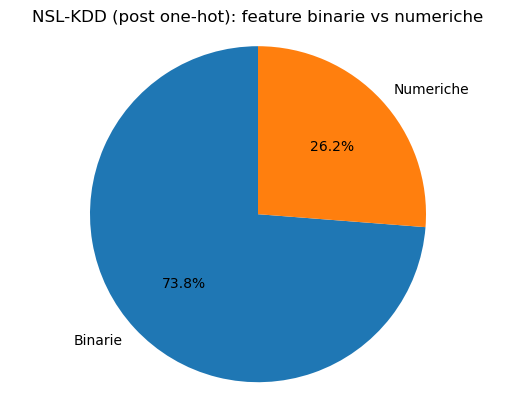

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def analyze_binary_numeric_features(
    X: pd.DataFrame,
    tol: float = 1e-8,
    sample_rows: int | None = None,
    include_quasi_binary: bool = False,
):
    """
    Analizza le feature di un DataFrame preprocessato (valori tipicamente in [0,1]).
    Classifica una colonna come:
      - 'binary' se tutti i valori sono in {0,1} (con tolleranza tol)
      - 'numeric' altrimenti

    Parametri:
      - X: pd.DataFrame (solo feature, niente label)
      - tol: tolleranza per float (es. 1e-8)
      - sample_rows: se vuoi accelerare, usa un campione di righe (es. 20000). None = usa tutto.
      - include_quasi_binary: se True, conta anche le colonne con valori quasi in {0,1}
        (utile se hai rumore floating tipo 0.99999999).

    Ritorna:
      - summary: dict con conteggi e percentuali
      - binary_cols: lista nomi colonne binarie
      - numeric_cols: lista nomi colonne numeriche
    """
    if not isinstance(X, pd.DataFrame):
        raise TypeError("X deve essere un pandas DataFrame.")

    X_work = X
    if sample_rows is not None and sample_rows < len(X):
        X_work = X.sample(n=sample_rows, random_state=42)

    # forza numeric (se hai qualche colonna object per errore)
    X_work = X_work.apply(pd.to_numeric, errors="coerce")

    binary_cols = []
    numeric_cols = []
    quasi_binary_cols = []

    for col in X_work.columns:
        col_vals = X_work[col].to_numpy()
        col_vals = col_vals[~np.isnan(col_vals)]  # ignora NaN

        if col_vals.size == 0:
            # Colonna vuota/NaN: trattala come numerica per sicurezza
            numeric_cols.append(col)
            continue

        # Check "binary": tutti vicini a 0 o 1 entro tol
        is_zero = np.isclose(col_vals, 0.0, atol=tol, rtol=0.0)
        is_one  = np.isclose(col_vals, 1.0, atol=tol, rtol=0.0)
        is_bin = np.all(is_zero | is_one)

        if is_bin:
            binary_cols.append(col)
        else:
            # opzionale: quasi-binary (molti valori ~0 o ~1)
            if include_quasi_binary:
                frac_binlike = np.mean(is_zero | is_one)
                if frac_binlike > 0.995:  # soglia conservativa
                    quasi_binary_cols.append(col)
                else:
                    numeric_cols.append(col)
            else:
                numeric_cols.append(col)

    total = len(X_work.columns)
    n_bin = len(binary_cols)
    n_num = len(numeric_cols)
    n_qb = len(quasi_binary_cols)

    if include_quasi_binary and n_qb > 0:
        # se vuoi separare quasi-binary nel report
        summary = {
            "total_features": total,
            "binary": n_bin,
            "quasi_binary": n_qb,
            "numeric": n_num,
            "binary_pct": 100.0 * n_bin / total,
            "quasi_binary_pct": 100.0 * n_qb / total,
            "numeric_pct": 100.0 * n_num / total,
        }
    else:
        summary = {
            "total_features": total,
            "binary": n_bin,
            "numeric": n_num,
            "binary_pct": 100.0 * n_bin / total,
            "numeric_pct": 100.0 * n_num / total,
        }

    return summary, binary_cols, numeric_cols, quasi_binary_cols


def plot_binary_numeric_pie(summary: dict, title: str = "NSL-KDD: Tipologia delle feature"):
    """
    Disegna un grafico a torta con matplotlib senza impostare colori.
    """
    if "quasi_binary" in summary and summary["quasi_binary"] > 0:
        labels = ["Binarie", "Quasi-binarie", "Numeriche"]
        sizes = [summary["binary"], summary["quasi_binary"], summary["numeric"]]
    else:
        labels = ["Binarie", "Numeriche"]
        sizes = [summary["binary"], summary["numeric"]]

    fig, ax = plt.subplots()
    ax.pie(sizes, labels=labels, autopct="%1.1f%%", startangle=90)
    ax.set_title(title)
    ax.axis("equal")  # cerchio perfetto
    plt.show()


# =========================
# ESEMPIO D'USO
# =========================
# Assumi di avere già i dati:
# X_train: pd.DataFrame con sole feature (122 colonne per NSL-KDD one-hot)
X_train_df = pd.DataFrame(
    X_train,
    columns=feature_names
)

summary, bin_cols, num_cols, qb_cols = analyze_binary_numeric_features(
    X_train_df,  # se è un DataFrame PyTorch, convertilo a pandas
    tol=1e-8,
    sample_rows=None,          # oppure 20000 per velocizzare
    include_quasi_binary=False # True se temi float quasi 0/1
)
print(summary)
plot_binary_numeric_pie(summary, title="NSL-KDD (post one-hot): feature binarie vs numeriche")

In [8]:
print(f"Type X_train: {X_train.dtype}")
print(f"Min: {X_train.min().item():.3f}, Max: {X_train.max().item():.3f}")


Type X_train: torch.float32
Min: 0.000, Max: 1.000


## 2. Create batches 

In [9]:
BATCH_SIZE = 256

if dataset.upper() == "MNIST":
    train_loader, test_loader = create_dataloaders(
        "MNIST",
        X_train, 
        Y_train, 
        X_test, 
        Y_test, 
        batch_size=BATCH_SIZE,
        device=device
    )

    # Verifica
    print("Batch di training MNIST:", len(train_loader))
else:
    train_loader, test_loader = create_dataloaders(
        "NSL_KDD",
        X_train, 
        Y_train, 
        X_test, 
        Y_test, 
        batch_size=BATCH_SIZE,
        device=device
    )

    # Verifica
    print("Batch di training NSL_KDD:", len(train_loader))


Creazione DataLoaders per NSL_KDD (Batch=256, Device=cpu)...
DataLoaders NSL-KDD pronti. Batch training: 277, Batch test: 89
Batch di training NSL_KDD: 277


In [10]:
print("TRAIN:", X_train.shape, "anom ratio:", Y_train.float().mean().item())
print("TEST :", X_test.shape,  "anom ratio:", Y_test.float().mean().item())
print("TEST counts:", torch.bincount(Y_test))

TRAIN: torch.Size([70887, 122]) anom ratio: 0.0499950610101223
TEST : torch.Size([22544, 122]) anom ratio: 0.5692423582077026
TEST counts: tensor([ 9711, 12833])


# RADON training 

## 1. Hyperparameters 

In [ ]:
# --- Esperimento ---
repetitions = 1

input_dim = X_train.shape[1]


if input_dim > 200:
    dim1, dim2 = 256, 128 
else:
    dim1, dim2 = 64, 32   

curriculum_start=None
curriculum_end=None
curriculum_min_S=None
consistency_weight=None
consistency_sigma=None

if dataset.upper() == "MNIST":
    curriculum_start=0.20
    curriculum_end=1.00
    curriculum_min_S=100

    consistency_weight=0.0
    consistency_sigma=0.02
else:
    if target_contamination <= 0.05:
        curriculum_start=0.05
        curriculum_end=0.40   
        curriculum_min_S=500   
        if target_contamination == 0.05:
        
            consistency_weight = 0.0 
            consistency_sigma  = 0.005
        else:
            consistency_weight=0.0 
            consistency_sigma=0.02
    else:
        curriculum_start=0.10
        curriculum_end=0.60    
        curriculum_min_S=1000   

        consistency_weight=0.0 
        consistency_sigma=0.01

print(f"Configurazione: Input={input_dim} -> Dim1={dim1} -> Dim2={dim2}")

fit_kwargs = dict(
    bin_estimator="knuth",
    epochs=200,
    projection_after_epochs_wu=25,
    projection_after_epochs_nl=50,
    batch_size=256,
    lr=1e-3,
    verbose=True,
    warmup_epochs=50,
    lambda_s=1.0,
    early_stopping=True,
    patience=2,
    curriculum_nl=True,
    curriculum_start=curriculum_start,
    curriculum_end=curriculum_end,
    curriculum_min_S=curriculum_min_S,
    consistency_weight=consistency_weight,
    consistency_sigma=consistency_sigma,
    ramp_enabled=True,
    ramp_epochs=50,
    return_stats=False,
)

🔧 Configurazione Rete: Input=122 -> Dim1=64 -> Dim2=32


In [12]:
train_time = [[] for i in range(repetitions)]
model = [[] for i in range(repetitions)]
loss = [[] for i in range(repetitions)]
th = [[] for i in range(repetitions)]
th_L = [[] for i in range(repetitions)]
th_S = [[] for i in range(repetitions)]

# Setup Debug
DEBUG_DUMP = False
DEBUG_DIR = r"C:\Users\giuse\Desktop\RADON_mnist\Results"

if dataset.upper() == "MNIST":
    DATASET_NAME = "MNIST"
else:
    DATASET_NAME = "NSL_KDD"

## 2. Import and train  RADON 

In [13]:
# Loop Repetitions
for i in range(repetitions):
    model[i] = RADON(input_dim, dim1, dim2).to(device).train()
    
    if DEBUG_DUMP:
        l, t, tl, ts, time_s = train_radon_debug(
            model[i], X_train,
            dataset_name=DATASET_NAME,
            repetition_index=i,
            debug_dir=DEBUG_DIR,
            device=device, input_dim=input_dim, dim1=dim1, dim2=dim2,
            **fit_kwargs
        )
    else:
        l, t, tl, ts, time_s = train_radon_simple(model[i], X_train, repetition_index=i, **fit_kwargs)


    loss[i], th[i], th_L[i], th_S[i], train_time[i] = l, t, tl, ts, time_s

    torch.save(
        model[i].state_dict(),
        f"C:/Users/giuse/Desktop/RADON_mnist/Trained_models/RADON_{DATASET_NAME}_Rep{i}.pth"
    )



--- [SIMPLE TRAIN] Repetition : 0 ---
[Mask] binary cols: 92/122
[Mask] numeric cols: 30/122
[OneHot] via=data | groups=0 | onehot_cols=0

Metadati esperimento (RADON warmup + NEG_LRN)
device: cpu
|X| = 70887 | dim = 122
epochs = 75 | proj_wu=25 | proj_nl=50
batch_size = 256 | lr = 0.001 | bin_estimator = knuth
warmup_epochs = 50  (WARMUP)
lambda_s = 1.0
param_norm_l2(init) = 9.806475e+00

Ep 001 [WARMUP(RADON)] | Loss=0.110800 | Lin=0.110800 | Ls(real)=0.000000 | λ=0 | Ratio(λ*Ls/Lin)=0.00x | S_real_sum=70887 | cos(Ŝ,S)=0.000 | cos(Ŝ,F(S))=0.000 | grad_norm=1.601e-02 | param_norm=1.367e+01 | time=1.83s
Ep 002 [WARMUP(RADON)] | Loss=0.008669 | Lin=0.008669 | Ls(real)=0.000000 | λ=0 | Ratio(λ*Ls/Lin)=0.00x | S_real_sum=70887 | cos(Ŝ,S)=0.000 | cos(Ŝ,F(S))=0.000 | grad_norm=6.902e-03 | param_norm=1.588e+01 | time=1.64s
Ep 003 [WARMUP(RADON)] | Loss=0.003933 | Lin=0.003933 | Ls(real)=0.000000 | λ=0 | Ratio(λ*Ls/Lin)=0.00x | S_real_sum=70887 | cos(Ŝ,S)=0.000 | cos(Ŝ,F(S))=0.000 | grad_nor

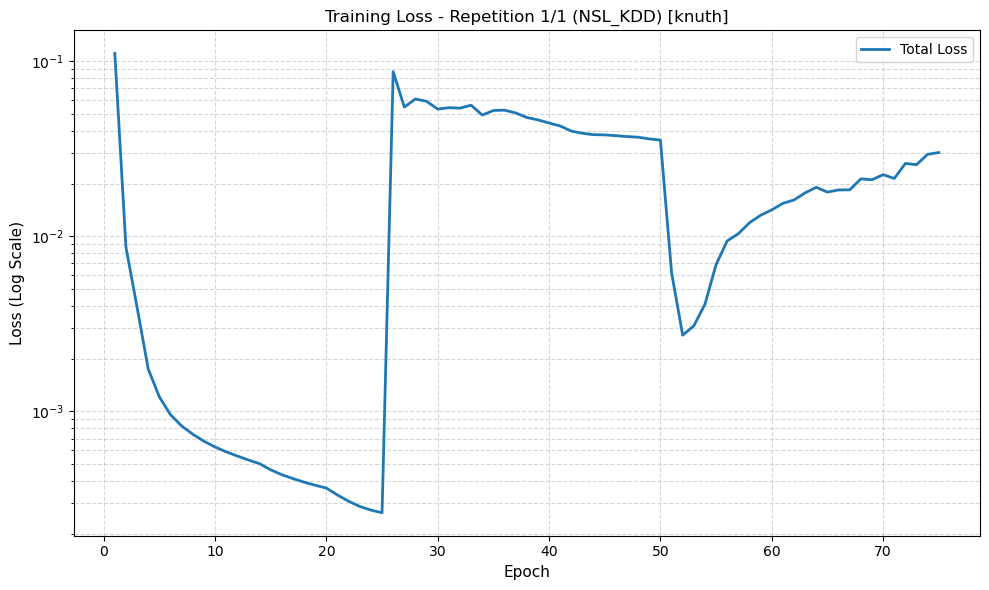

In [14]:
if DATASET_NAME == "MNIST":
    plot_training_losses(
        loss,               
        warmup_epochs=50,      
        dataset_name="MNIST", 
        bin_estimator="knuth"
    )
else:
    plot_training_losses(
        loss,
        warmup_epochs=100,
        dataset_name="NSL_KDD",
        bin_estimator="knuth"
    )

# RADON Test 

## 1. Test samples reconstruction error

In [15]:
print("TEST anomaly ratio:", Y_test.float().mean().item())


TEST anomaly ratio: 0.5692423582077026


Valutazione sul test set: NSL_KDD
Rep 1/1: score [0.0001, 0.3525] media=0.0267 | label=0:9711, 1:12833
Generazione boxplot


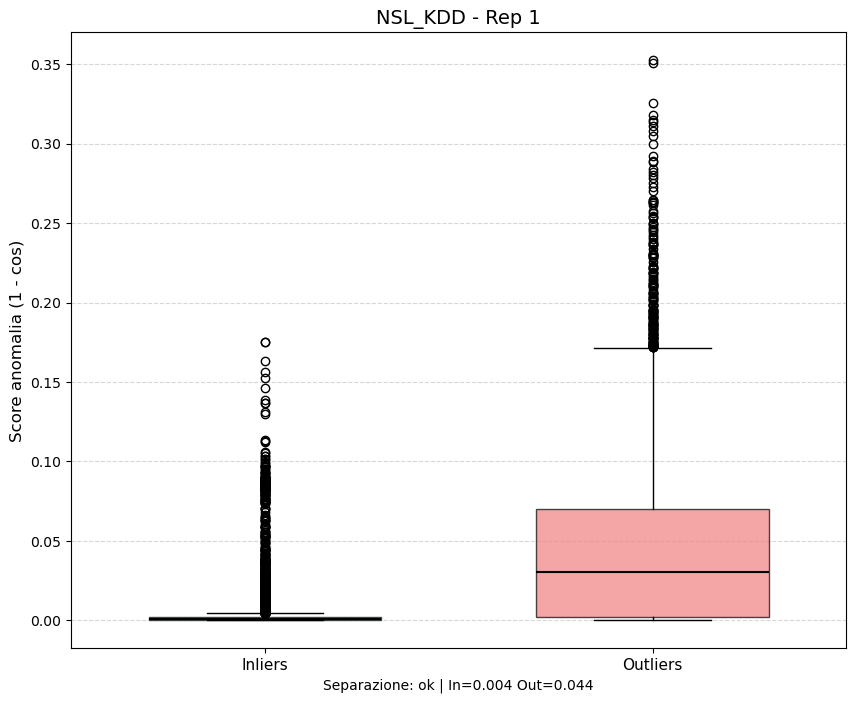

In [16]:
if dataset.upper() == "MNIST":
    test_scores, test_labels, test_pred = evaluate_and_plot(
        models=model,
        test_loader=test_loader,
        input_dim=input_dim,
        device=device,
        dataset_name="MNIST",
        normal_digit=4,
        threshold_S_cos=th_S[0][-1]
    )
else:
    test_scores, test_labels, test_pred = evaluate_and_plot(
        models=model,          
        test_loader=test_loader, 
        input_dim=input_dim,
        device=device,
        dataset_name="NSL_KDD",
        threshold_S_cos=th_S[0][-1]
    )

## 2. Test AUROC (Area Under the Receiver Operating Characteristic Curve)

Generazione curve ROC per NSL_KDD


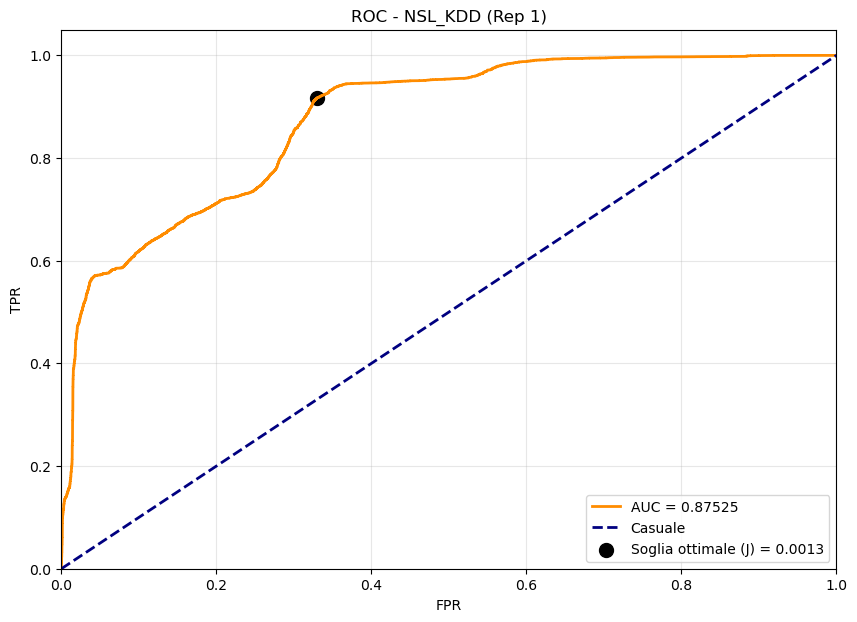

NSL_KDD: media=0.87525 ± 0.00000 | valori=[0.8752531981641045]


In [17]:
if DATASET_NAME == "MNIST":
    aucroc_results = plot_aucroc(test_scores, test_labels, dataset_name="MNIST")
else:
     aucroc_results = plot_aucroc(test_scores, test_labels, dataset_name="NSL_KDD")

## 3. Test AUPRC (Area Under the Precision Recall Curve)

Generazione curve Precision-Recall per NSL_KDD


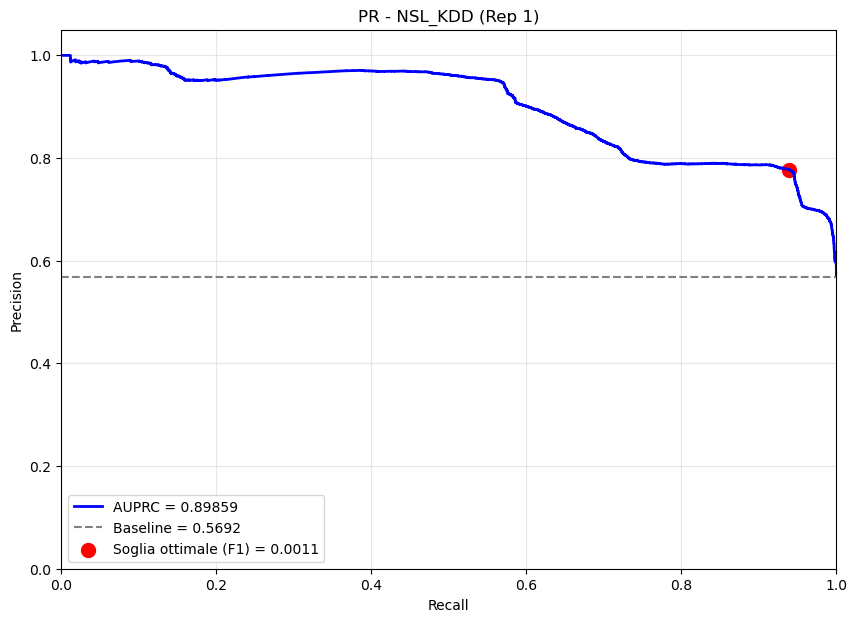

NSL_KDD: media=0.89859 ± 0.00000 | valori=[0.8985948953569698]


In [18]:
if DATASET_NAME == "MNIST":
    auprc_results = plot_auprc(test_scores, test_labels, dataset_name="MNIST")
else:
     auprc_results = plot_auprc(test_scores, test_labels, dataset_name="NSL_KDD")

# Explainability

In [19]:
fp_idx = (test_pred[0] == 1) & (test_labels[0] == 0)
fn_idx = (test_pred[0] == 0) & (test_labels[0] == 1)
print("Falsi Positivi:", fp_idx.sum().item())
print("Falsi Negativi:", fn_idx.sum().item())


Falsi Positivi: 0
Falsi Negativi: 12833



Audit categorico:
  - service        X osservato=[service_telnet=1.00] -> baseline=http Dscore=-0.0177
Mismatch: 1/1 gruppi differiscono dalla baseline

Summary: ANOMALY | score=0.2427
Ablazione categorica (Dscore):
  - service       : [telnet=1.00] -> http  Dscore=-0.0177

Ablazione numerica (Dscore):
  - dst_host_srv_rerror_rate    : x=0.690 clip=[0.000,0.300] (out) Dscore=-0.0508
  - diff_srv_rate               : x=0.670 clip=[0.000,0.030] (out) Dscore=-0.0301
  - same_srv_rate               : x=0.670 clip=[0.990,1.000] (out) Dscore=-0.0220

Violazioni ricostruzione (top 3):
  - logged_in                   : x=0.000 xhat=0.830 |x-xhat|=0.830 |(1-x)-xhat|=0.170 NL
  - diff_srv_rate               : x=0.670 xhat=0.027 |x-xhat|=0.643 |(1-x)-xhat|=0.303 NL
  - srv_diff_host_rate          : x=0.500 xhat=0.010 |x-xhat|=0.490 |(1-x)-xhat|=0.490 
Check NL: 4/10 feature preferiscono target negativo


Ablazione numerica (Dscore)
feature                        |      x |   xhat |         [ql,q

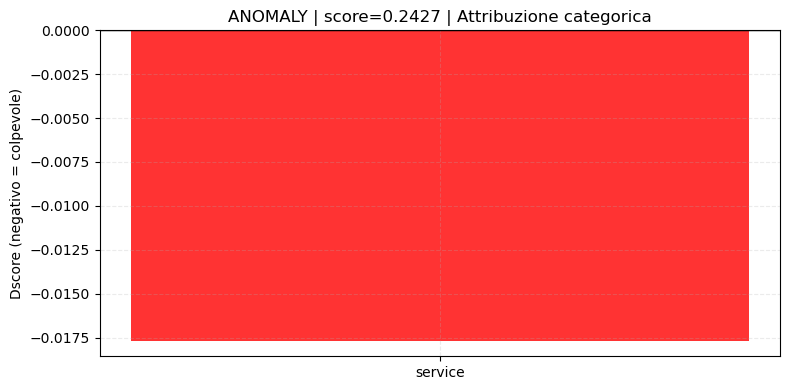

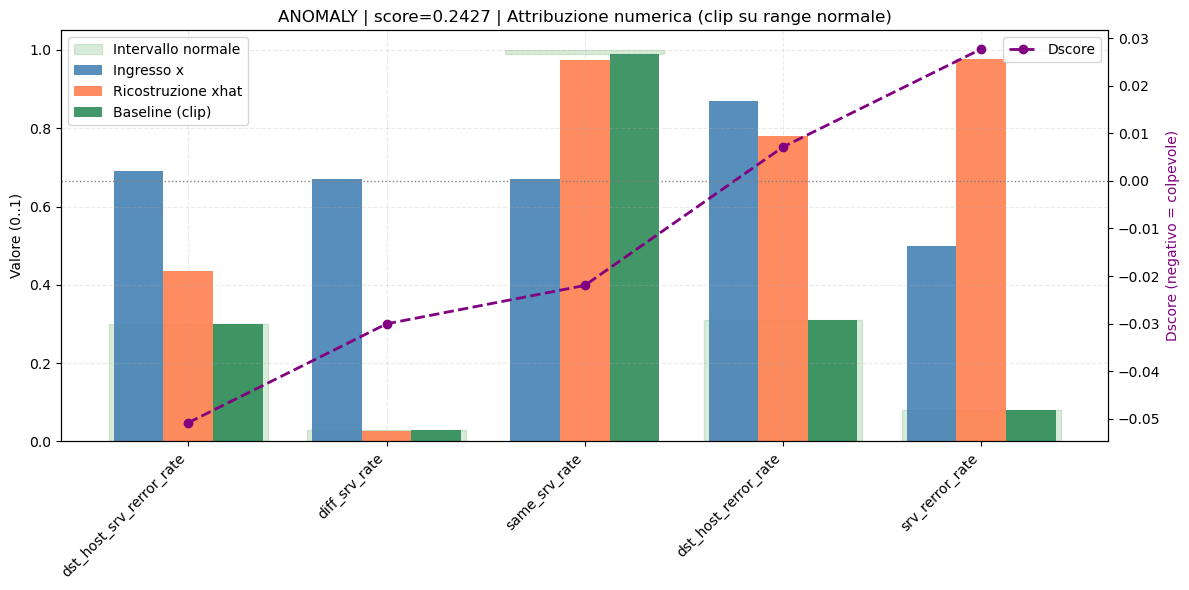

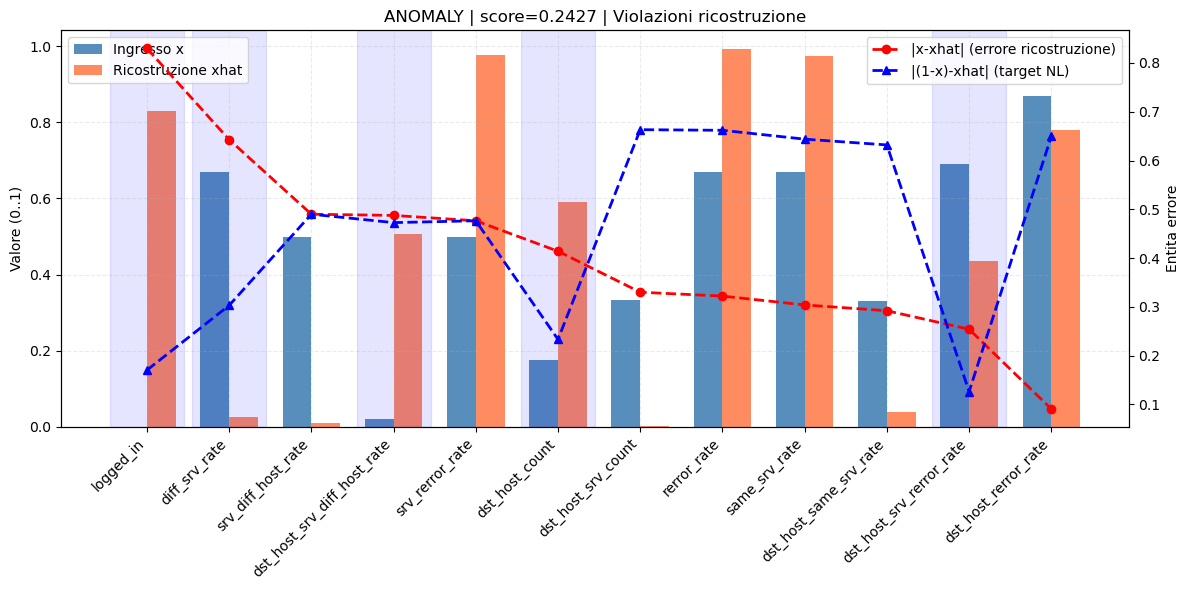


Summary: NORMAL | score=0.0002

Violazioni ricostruzione (top 3):
  - dst_host_count              : x=1.000 xhat=0.946 |x-xhat|=0.054 |(1-x)-xhat|=0.946 
  - srv_diff_host_rate          : x=0.000 xhat=0.026 |x-xhat|=0.026 |(1-x)-xhat|=0.974 
  - dst_host_srv_count          : x=1.000 xhat=0.977 |x-xhat|=0.023 |(1-x)-xhat|=0.977 
Check NL: 0/10 feature preferiscono target negativo


Violazioni ricostruzione (|x-xhat|)
feature                        |      x |   xhat | |x-xhat| | |(1-x)-xhat| | pref
dst_host_count                 |  1.000 |  0.946 |    0.054 |        0.946 |  POS
srv_diff_host_rate             |  0.000 |  0.026 |    0.026 |        0.974 |  POS
dst_host_srv_count             |  1.000 |  0.977 |    0.023 |        0.977 |  POS
dst_host_same_srv_rate         |  1.000 |  0.981 |    0.019 |        0.981 |  POS
logged_in                      |  1.000 |  0.984 |    0.016 |        0.984 |  POS
dst_host_same_src_port_rate    |  0.000 |  0.008 |    0.008 |        0.992 |  POS
srv_c

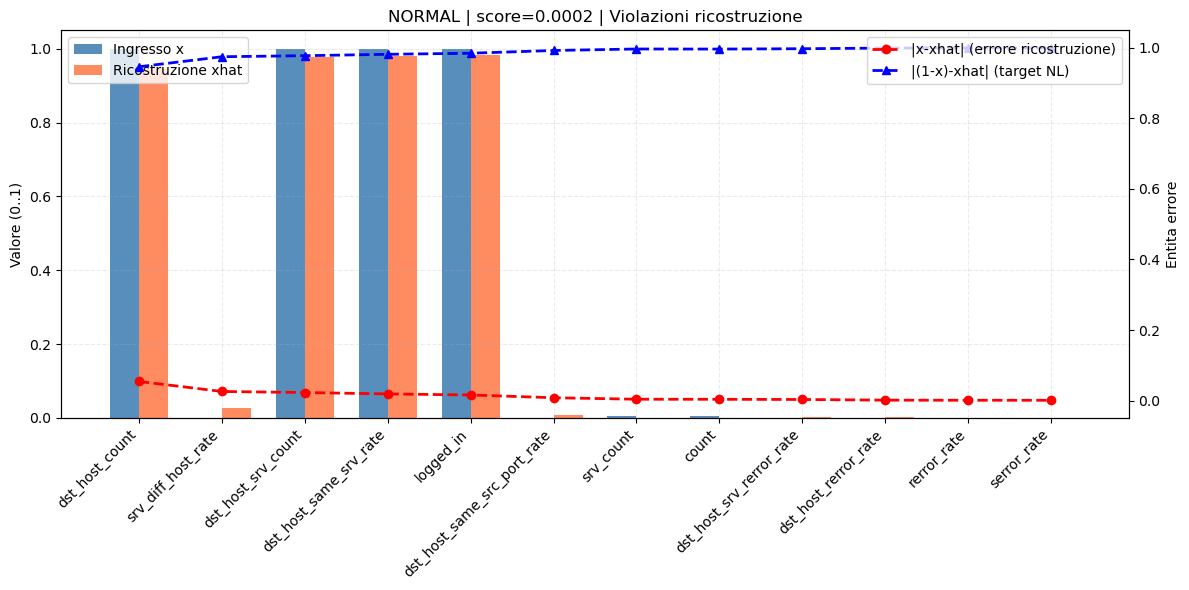


Summary: NORMAL | score=0.0002

Violazioni ricostruzione (top 3):
  - dst_host_count              : x=1.000 xhat=0.946 |x-xhat|=0.054 |(1-x)-xhat|=0.946 
  - srv_diff_host_rate          : x=0.000 xhat=0.026 |x-xhat|=0.026 |(1-x)-xhat|=0.974 
  - dst_host_srv_count          : x=1.000 xhat=0.977 |x-xhat|=0.023 |(1-x)-xhat|=0.977 
Check NL: 0/10 feature preferiscono target negativo


Violazioni ricostruzione (|x-xhat|)
feature                        |      x |   xhat | |x-xhat| | |(1-x)-xhat| | pref
dst_host_count                 |  1.000 |  0.946 |    0.054 |        0.946 |  POS
srv_diff_host_rate             |  0.000 |  0.026 |    0.026 |        0.974 |  POS
dst_host_srv_count             |  1.000 |  0.977 |    0.023 |        0.977 |  POS
dst_host_same_srv_rate         |  1.000 |  0.981 |    0.019 |        0.981 |  POS
logged_in                      |  1.000 |  0.984 |    0.016 |        0.984 |  POS
dst_host_same_src_port_rate    |  0.000 |  0.008 |    0.008 |        0.992 |  POS
srv_c

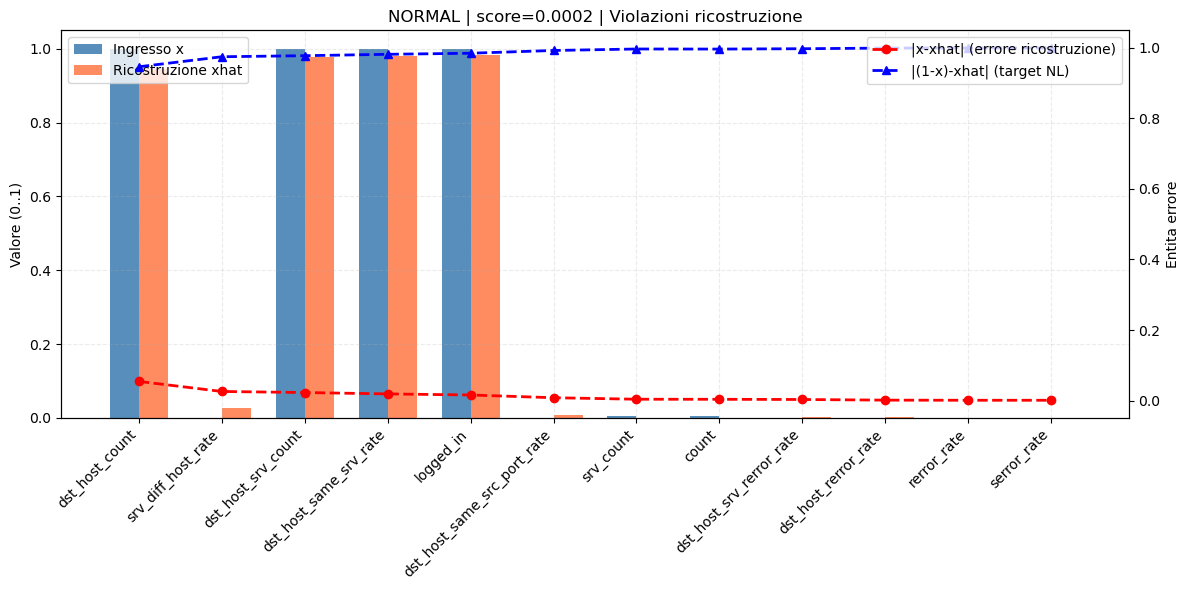


Audit categorico:
  - service        X osservato=[service_finger=1.00] -> baseline=http Dscore=-0.0062
Mismatch: 1/1 gruppi differiscono dalla baseline

Summary: NORMAL (borderline) | score=0.1389
Ablazione categorica (Dscore):
  - service       : [finger=1.00] -> http  Dscore=-0.0062

Ablazione numerica (Dscore):
  - dst_host_srv_diff_host_rate : x=0.200 clip=[0.000,0.100] (out) Dscore=+0.0033

Violazioni ricostruzione (top 3):
  - srv_diff_host_rate          : x=1.000 xhat=0.001 |x-xhat|=0.999 |(1-x)-xhat|=0.001 NL
  - dst_host_srv_diff_host_rate : x=0.200 xhat=0.767 |x-xhat|=0.567 |(1-x)-xhat|=0.033 NL
  - dst_host_count              : x=0.290 xhat=0.237 |x-xhat|=0.053 |(1-x)-xhat|=0.472 
Check NL: 2/10 feature preferiscono target negativo


Ablazione numerica (Dscore)
feature                        |      x |   xhat |         [ql,qh] | out |   Dscore | |x-xhat| | |(1-x)-xhat| | pref
dst_host_srv_diff_host_rate    |  0.200 |  0.767 | [0.000,0.100] |  si |  +0.0033 |    0.567 |     

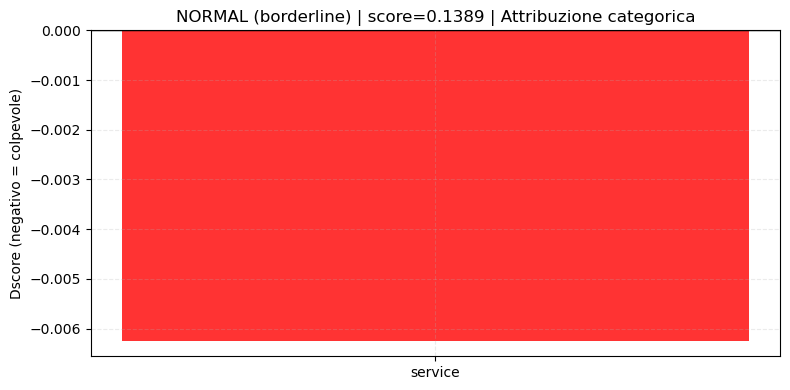

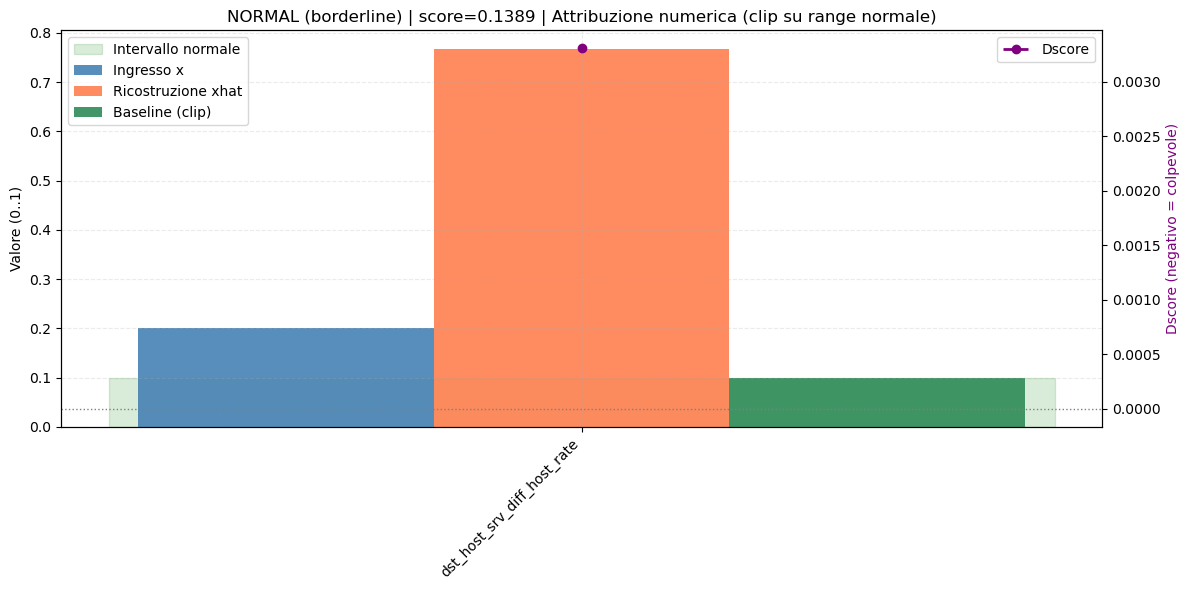

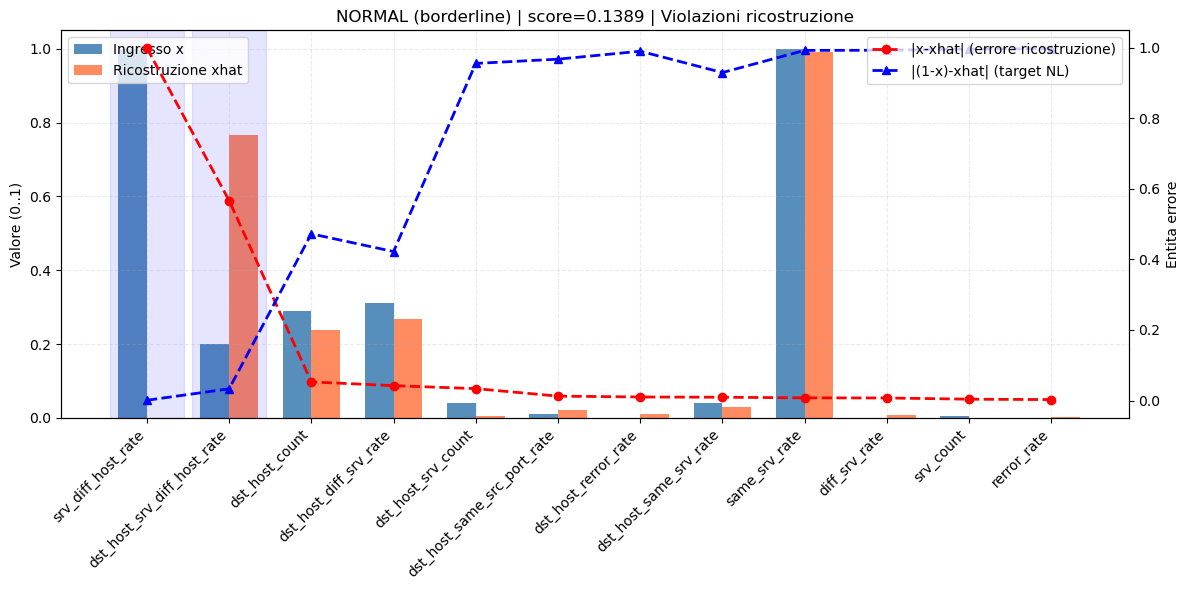

In [20]:
if dataset.upper() == "MNIST":
    visualize_mnist_reconstruction(model[0], test_loader, device, num_samples=3)
else:
    explain_nslkdd(
        model=model[0],
        test_loader=test_loader,
        input_dim=input_dim,
        device=device,
        X_train=X_train,
        y_train=Y_train,
        feature_names=feature_names,
        q_low=0.05, q_high=0.95,
        top_k_num=12,
        top_k_groups=3,
        n_anom=1,
        n_norm=2,
        add_borderline_norm=True
    )